# Q-Learning with Frozen Lake (Gymnasium)

#### In this notebook we will present the training of a RL agent for the Frozen Lake problem.


## Environment description
- Possible actions:
    - 0: Left
    - 1: Down
    - 2: Right
    - 3: Up
- Observation Space: 4x4 grid. There are 16 possible observations.
- Rewards:
    - 1 if the agent reaches the goal
    - 0 if the agent falls in a hole
    - 0 if the agent is in ice
 

![FrozenUrl](https://gymnasium.farama.org/_images/frozen_lake.gif "frozen")


## Code
### Install and import resources

In [1]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
import pandas as pd
import math

np.random.seed(12345)

### Create Frozen Lake environment
Frozen lake has the following parameters:

1. `desc=None`: Used to specify non-preloaded maps.  If `desc=None` then `map_name` will be used. If both `desc` and `map_name` are `None` a random 8x8 map with 80% of locations frozen will be generated. To Specify a custom map - `desc=["SFFF", "FHFH", "FFFH", "HFFG"]` The tile letters denote:

    * “S” for Start tile

    * “G” for Goal tile
    
    * “F” for frozen tile

    * “H” for a tile with a hole
    
    A random generated map can be specified by calling the function `generate_random_map`.

2. `map_name="4x4"` - Helps load two predefined map names (4x4 and 8x8)

3. `is_slippery=True` If true the player will move in intended direction with probability specified by the `success_rate` else will move in either perpendicular direction with equal probability in both directions.

4. `success_rate=1.0/3.0`: Probability of success if the floor is slippery.

5. `reward_schedule=(1,0,0)`: Specifies the reward amount for certain tiles (Reach Goal, Reach Hole, Reach Frozen). 

6. `render_mode="human"`: allows graphic visualisation of the environment. 

In [2]:
# Create env
env = gym.make("FrozenLake-v1",
                desc = ["SFFF", "FHFH", "FFFH", "HFFG"],
                is_slippery = False,
                #render_mode = "human",
)

# Actions
action_names = {0:'Left', 1:'Down', 2:'Right', 3:'Up'}
action_space_size = env.action_space.n

# States
state_space_size = env.observation_space.n

print('Environment:\n{}\n States: {}\n Actions:{}'.format(env.get_wrapper_attr('desc'),state_space_size, action_space_size))

Environment:
[[b'S' b'F' b'F' b'F']
 [b'F' b'H' b'F' b'H']
 [b'F' b'F' b'F' b'H']
 [b'H' b'F' b'F' b'G']]
 States: 16
 Actions:4


In [3]:
q_table = np.zeros((env.observation_space.n, env.action_space.n))

# Visualization
Q_t = pd.DataFrame(data = q_table, columns = ['Left','Down','Right','Up'])
Q_t.index = [i+1 for i in range (len(Q_t))]
Q_t.columns.name = 'State'

Q_t

State,Left,Down,Right,Up
1,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0
10,0.0,0.0,0.0,0.0


## Useful functions
Here we will define the different functions needed to solve the problem.


In [4]:
# We want a dynamic learning rate
def learning_rate(n:int, min_rate = 0.01) -> float:
    """Lr decay for each episode"""
    return max(min_rate, min(1.0, 1.0-math.log10((n+1)/25)))

def exploration_rate(n:int,min_rate = 0.01) ->float:
    """Exploration rate decays with time (better exploit at the end)"""
    return max(min_rate, min(1.0, 1.0-math.log10((n+1)/25)))

def e_greedy_pol(current_state:tuple):
    # Explore
    if np.random.random() < exploration_rate(e):
        action = env.action_space.sample()
    # Exploit    
    else:
        action = np.argmax(q_table[current_state])
    return action

def update_Q(reward: float, action, current_state, new_state: tuple, discount_factor=1) ->float:
    act_val = q_table[current_state, action]
    fut_val = np.max(q_table[new_state])
    learned_value = reward + discount_factor * fut_val- act_val
    new_val = (1-lr)*act_val + lr*(learned_value)

    return new_val



In [11]:
# Learning
ep_num = []    #Episodes
ep_sc = []     #Scores

n_episodes = 1000

for e in range(1, n_episodes+1):
    # Initial state
    current_state = env.reset()[0]
    done = False
    ep_num.append(e)
    score = 0

    actions = []
    while done == False:
        # Choose action
        action = e_greedy_pol(current_state)
        actions.append(action_names[action])

        # Environment update
        obs, reward, done , _, _ = env.step(action)

        new_state = obs
        score += reward
        lr = learning_rate(e)

        # Update q-table
        q_table[current_state, action] = update_Q(reward, action, current_state, new_state)

        # Update state
        current_state = new_state

    ep_sc.append(score)

    # Print results each 100 states
    if e % 100 == 0:
        sc = ep_sc[e-1]

        print ('Episode {}\n\tScore:{}; Actions:{}'.format(e, score, actions))

Episode 100
	Score:0; Actions:['Down', 'Left', 'Left', 'Down', 'Down']
Episode 200
	Score:1; Actions:['Down', 'Down', 'Right', 'Down', 'Right', 'Up', 'Down', 'Right']
Episode 300
	Score:1; Actions:['Down', 'Down', 'Right', 'Down', 'Right', 'Right']
Episode 400
	Score:1; Actions:['Down', 'Down', 'Right', 'Down', 'Right', 'Right']
Episode 500
	Score:1; Actions:['Down', 'Down', 'Right', 'Down', 'Right', 'Right']
Episode 600
	Score:1; Actions:['Down', 'Down', 'Right', 'Down', 'Right', 'Right']
Episode 700
	Score:1; Actions:['Down', 'Down', 'Right', 'Down', 'Right', 'Right']
Episode 800
	Score:1; Actions:['Down', 'Down', 'Right', 'Down', 'Right', 'Right']
Episode 900
	Score:1; Actions:['Down', 'Down', 'Right', 'Down', 'Right', 'Right']
Episode 1000
	Score:1; Actions:['Down', 'Down', 'Right', 'Down', 'Right', 'Right']


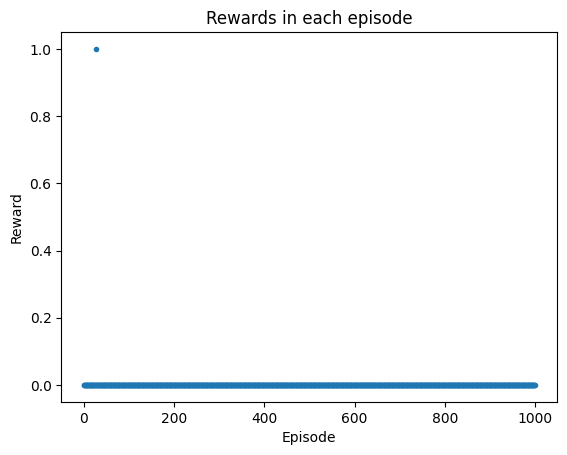

In [10]:
plt.plot(ep_sc,'.')
plt.title('Rewards in each episode')
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.show()

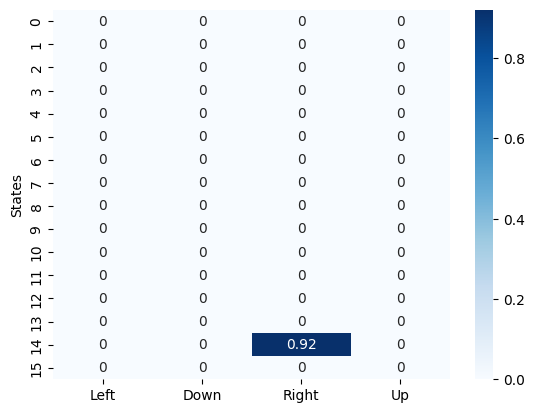

In [7]:
from seaborn import heatmap

data = pd.DataFrame(data=q_table, columns=['Left', 'Down', 'Right', 'Up'])
heatmap(data, cmap='Blues', annot=True, square=False)
plt.ylabel('States')
plt.show()

## Test

In [8]:
n_episodes_t = 5

for e in range(1, n_episodes_t+1):

    current_state = env.reset()[0]
    done = False
    score = 0

    actions = []
    while done==False:
        
        # policy
        action = np.argmax(q_table[current_state]) #always exploit
        actions.append(action_names[action])

        # Result of action
        obs, reward, done, _,_= env.step(action)
        score += reward

        # new state 
        current_state = obs

    print('Episode: {}\n\tActions: {}; Score: {}'.format(e, actions, score))

env.close()

KeyboardInterrupt: 